# Multiple Linear Regression

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

In [3]:
# Importing the dataset and loading it into postgreSQL
engine = create_engine("postgresql+psycopg2://postgres@localhost:5432/postgres")

df = pd.read_csv("insurance.csv")
df.to_sql("insurance", engine, if_exists="replace", index=False)
pd.read_sql("select count(*) from insurance", engine)

,count
0,1338


In [4]:
print(df.head())
print(df.info()) 
print(df.describe())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000 

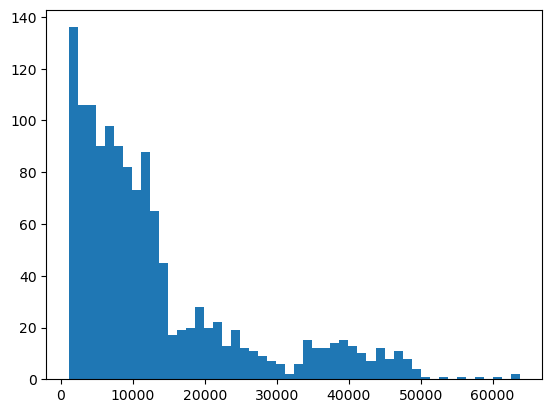

In [5]:
plt.hist(df['charges'], bins=50)
plt.show()

In [6]:
pd.read_sql("select smoker, avg(charges), count(*) from insurance group by smoker;", engine)

,smoker,avg,count
0,yes,32050.231832,274
1,no,8434.268298,1064


In [7]:
pd.read_sql("select region, avg(charges), count(*) from insurance group by region;", engine)

,region,avg,count
0,northwest,12417.575374,325
1,southeast,14735.411438,364
2,northeast,13406.384516,324
3,southwest,12346.937377,325


In [8]:
pd.read_sql("select case when bmi < 25 then 'normal' when bmi >= 25 and bmi <= 30 then 'overweight' else 'obese' end as bmi_category, avg(charges), count(*) from insurance group by bmi_category;", engine)

,bmi_category,avg,count
0,overweight,10995.430253,388
1,normal,10282.224474,245
2,obese,15560.926321,705


In [19]:
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)

In [18]:
# Preparing the dataset for the model
df = pd.read_sql("select * from insurance;", engine)
df['sex'] = df['sex'].map({'male': 1, 'female': 0})
df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})
df = df[['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']]

df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,northwest,10600.54830
1334,18,0,31.920,0,0,northeast,2205.98080
1335,18,0,36.850,0,0,southeast,1629.83350
1336,21,0,25.800,0,0,southwest,2007.94500


In [45]:
cols = [c for c in df.columns if c != "charges"] + ["charges"]
df = df[cols]

df

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,smoker_bmi,charges
0,19,0,27.900,0,1,0,0,1,27.90,16884.92400
1,18,1,33.770,1,0,0,1,0,0.00,1725.55230
2,28,1,33.000,3,0,0,1,0,0.00,4449.46200
3,33,1,22.705,0,0,1,0,0,0.00,21984.47061
4,32,1,28.880,0,0,1,0,0,0.00,3866.85520
...,...,...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,0,0,0.00,10600.54830
1334,18,0,31.920,0,0,0,0,0,0.00,2205.98080
1335,18,0,36.850,0,0,0,1,0,0.00,1629.83350
1336,21,0,25.800,0,0,0,0,1,0.00,2007.94500


In [46]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

print(X)

[[19.    0.   27.9  ...  0.    1.   27.9 ]
 [18.    1.   33.77 ...  1.    0.    0.  ]
 [28.    1.   33.   ...  1.    0.    0.  ]
 ...
 [18.    0.   36.85 ...  1.    0.    0.  ]
 [21.    0.   25.8  ...  0.    1.    0.  ]
 [61.    0.   29.07 ...  0.    0.   29.07]]


In [47]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [48]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
y_pred = regressor.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error: {rmse}")
print(f"Mean Absolute Error: {mae}")
print(f"R-squared: {r2}")


Root Mean Squared Error: 4573.807686290383
Mean Absolute Error: 2756.8986595179617
R-squared: 0.8652503208873079


.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [24]:
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB

row = pd.DataFrame([{
    "project": "p2_insurance",
    "model": "mlr_baseline",
    "params": {"features": [c for c in df.columns if c != "charges"], "test_size": 0.2, "random_state": 42},
    "rmse": float(rmse),
    "mae": float(mae),
    "r2": float(r2),
    "run_at": datetime.now(),
}])
row.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

In [25]:
print(regressor.coef_)


[ 2.56975706e+02 -1.85916916e+01  3.37092552e+02  4.25278784e+02
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]


In [51]:
import statsmodels.api as sm
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     592.0
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:19:14   Log-Likelihood:                -10609.
No. Observations:                1070   AIC:                         2.124e+04
Df Residuals:                    1060   BIC:                         2.129e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2041.6600    982.114     -2.079      0.038   -3968.769    -114.551
x1           263.3906     10.811     24.363      0.000     242.177     284.604
x2          -525.2309    302.379     -1.737      0.083   -1118.560      68.098
x3            20.2508     29.124      0.695      0.487     -36.896      77.397
x4           463.6526    124.030      3.738      0.000     220.281     707.024
x5         -2.121e+04   1884.403    -11.254      0.000   -2.49e+04   -1.75e+04
x6          -631.4164    430.658     -1.466      0.143   -1476.455     213.622
x7          -967.4805    433.052     -2.234      0.026   -1817.216    -117.745
x8         -1233.4264    429.543     -2.871      0.004   -2076.278    -390.575
x9          1470.8625     60.558     24.288      0.000    1352.035    1589.691
==============================================================================
Omnibus:                      571.326   Durbin-Watson:                   2.073
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3356.002
Skew:                           2.496   Prob(JB):                         0.00
Kurtosis:                      10.096   Cond. No.                         669.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.DataFrame()
X_const = sm.add_constant(X_train)


vif["VIF Factor"] = [variance_inflation_factor(X_const, i) for i in range(X_const.shape[1])]
vif["features"] = ["const"] + [c for c in df.columns if c != "charges"]
vif

,VIF Factor,features
0,35.353322,const
1,1.023084,age
2,1.006303,sex
3,1.094986,bmi
4,1.005643,children
5,1.011703,smoker
6,1.493159,region_northwest
7,1.613285,region_southeast
8,1.515246,region_southwest


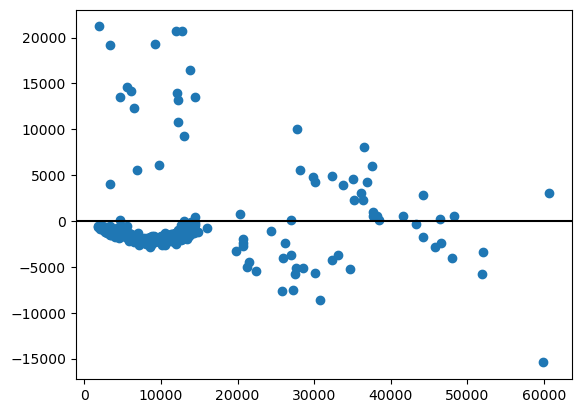

In [49]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color="black")

In [30]:
y_train_log = np.log(y_train)

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)

y_pred_log = model_log.predict(X_test)
y_pred_dollars = np.exp(y_pred_log)

rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_dollars))
mae_log = mean_absolute_error(y_test, y_pred_dollars)
r2_log = r2_score(y_test, y_pred_dollars)

print(f"Root Mean Squared Error: {rmse_log}")
print(f"Mean Absolute Error: {mae_log}")
print(f"R-squared: {r2_log}")

Root Mean Squared Error: 7815.307271065264
Mean Absolute Error: 3888.770780515877
R-squared: 0.6065730962548823


.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [34]:
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB

row = pd.DataFrame([{
    "project": "p2_insurance",
    "model": "mlr_log",
    "params": {"features": [c for c in df.columns if c != "charges"], "target": "log(charges)", "test_size": 0.2, "random_state": 42},
    "rmse": float(rmse_log),
    "mae": float(mae_log),
    "r2": float(r2_log),
    "run_at": datetime.now(),
}])
row.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

In [36]:
pd.read_sql("select model, r2, rmse, mae from model_results where project='p2_insurance'", engine)

,model,r2,rmse,mae
0,mlr_baseline,0.783593,5796.284659,4181.194474
1,mlr_log,0.606573,7815.307271,3888.770781


In [38]:
df['smoker_bmi'] = df['smoker'] * df['bmi']

In [43]:
df[['smoker', 'bmi', 'smoker_bmi']].head()

,smoker,bmi,smoker_bmi
0,1,27.900,27.9
1,0,33.770,0.0
2,0,33.000,0.0
3,0,22.705,0.0
4,0,28.880,0.0


In [50]:
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB

row = pd.DataFrame([{
    "project": "p2_insurance",
    "model": "mlr_interaction",
    "params": {"features": [c for c in df.columns if c != "charges"], "test_size": 0.2, "random_state": 42},
    "rmse": float(rmse),
    "mae": float(mae),
    "r2": float(r2),
    "run_at": datetime.now(),
}])
row.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

In [53]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(regressor, X, y, cv=5, scoring="neg_root_mean_squared_error")
print(scores)

[-4629.22584884 -5198.13856163 -4184.58036794 -5196.43915878
 -5043.7107612 ]


.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-pack

In [55]:
print((-scores).mean())
print((-scores).std())

4850.418939676832
392.49663510168665
